# 1 · Data, patients and the federated idea

**Question:** What is being classified, and what makes this a federated experiment?

For readers who know the basic idea of classification. In about five minutes,
we will connect ECG beats to patient clients, inspect the class imbalance, and
check the separation between training and testing. Every plot below uses the
small, versioned tables already in this repository. There is no download or training.

**Route:** task → patient split → unequal clients → a useful baseline.

[Notebook guide](README.md) · [Exact data preparation](../docs/data.md)

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'fedecg/models.py').is_file())
sys.path.insert(0, str(ROOT))
from notebooks._support import CLASSES, COLORS, NAMES, read_table, read_json, setup, finish
setup()
%matplotlib inline

## A heartbeat becomes a five-class prediction

The public [MIT-BIH 1.0.0 data](https://physionet.org/content/mitdb/1.0.0/)
provide ECG signals and expert beat annotations. An annotated peak defines a
252-sample window: 90 samples before it and 162 from it onward, at 360 Hz.
Each window is normalized separately. The classifier predicts N, S, V, F or Q.

Expert peak locations are inputs to this task. A beat detector is outside this
evaluation. The optional four RR features describe **past** beat intervals;
the waveform itself includes samples after the peak.

In [2]:
mapping = pd.DataFrame({
    'Class': CLASSES,
    'Meaning': ['Normal/conduction-related', 'Supraventricular ectopic',
                'Ventricular ectopic', 'Fusion', 'Unknown/unclassifiable group'],
    'Annotation symbols': ['N L R e j', 'A a J S', 'V E', 'F', '/ f Q']})
display(mapping.set_index('Class'))
support = read_table('main_patient_class_support.csv')
split_counts = support.pivot_table(index='split', columns='class', values='beats', aggfunc='sum')
split_counts = split_counts.reindex(index=['training', 'validation', 'test'], columns=CLASSES)
display(split_counts.assign(Total=split_counts.sum(axis=1)).astype(int))
assert split_counts.sum(axis=1).tolist() == [40142, 8897, 49692]

,Meaning,Annotation symbols
Class,,
N,Normal/conduction-related,N L R e j
S,Supraventricular ectopic,A a J S
V,Ventricular ectopic,V E
F,Fusion,F
Q,Unknown/unclassifiable group,/ f Q


class,N,S,V,F,Q,Total
split,,,,,,
training,36723,421,2582,408,8,40142
validation,7490,395,1008,4,0,8897
test,44240,1837,3220,388,7,49692


## What do the normalized beats look like?

These are **training-only class means**, with a band of one waveform standard
deviation. They summarize all training beats in each class, after the same
per-beat normalization used by the models. The time axis is relative to the
annotated peak. The band shows waveform variation, not uncertainty in the mean.

The small Q support makes its average especially fragile. These aggregates
are illustrations of this dataset, not universal diagnostic templates. Source:
[MIT-BIH 1.0.0, PhysioNet](https://physionet.org/content/mitdb/1.0.0/).

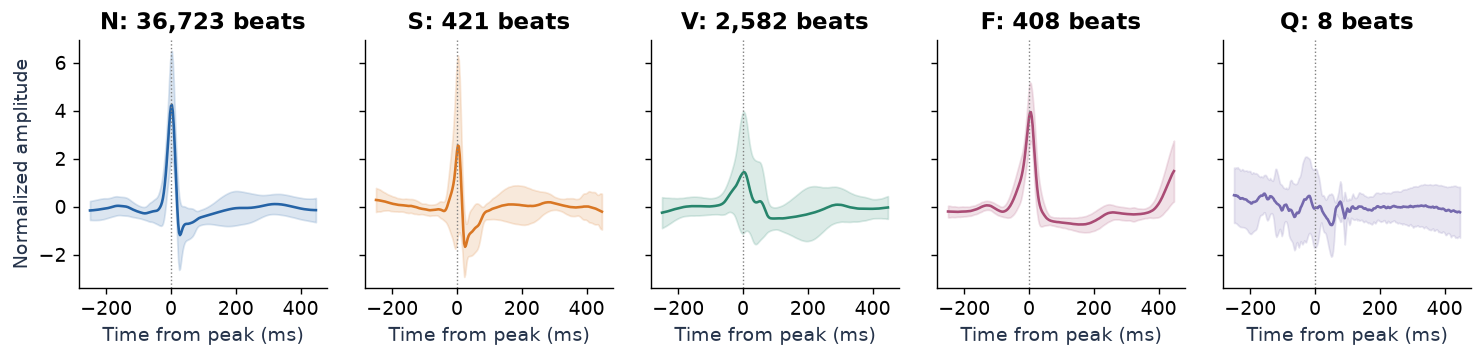

In [3]:
waves = pd.read_csv(ROOT / 'notebooks/data/training_waveform_summary.csv')
fig, axes = plt.subplots(1, 5, figsize=(12, 3), sharex=True, sharey=True)
for ax, label, color in zip(axes, CLASSES, COLORS):
    values = waves[waves['class'].eq(label)]
    ax.plot(values.time_ms, values['mean'], color=color)
    ax.fill_between(values.time_ms, values['mean'] - values.sd,
                    values['mean'] + values.sd, color=color, alpha=.16)
    ax.axvline(0, color='gray', ls=':', lw=.8)
    ax.set(title=f"{label}: {int(values.training_beats.iloc[0]):,} beats", xlabel='Time from peak (ms)')
axes[0].set_ylabel('Normalized amplitude')
finish(fig)

## Separate people before separating beats

Beats from one person resemble each other. Assigning individual beats at random
can put the same person's ECG patterns on both sides of an evaluation.
Here the primary split uses **17 training patients, four validation patients
and 22 test patients**. Record 201 is excluded from training because it shares
a subject with test record 202. The older canonical split remains only in
separately labelled diagnostic runs.

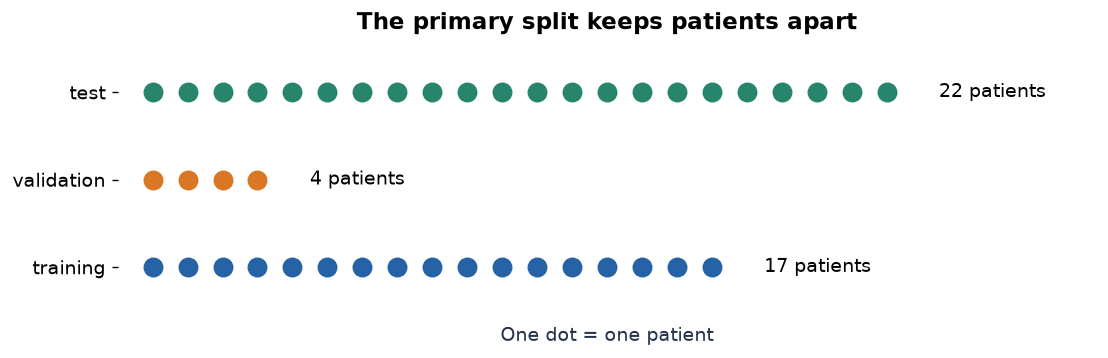

In [4]:
patients = {s: set(support.loc[support['split'].eq(s), 'record']) for s in split_counts.index}
assert len(patients['training']) == 17 and len(patients['test']) == 22
assert 201 not in patients['training'] and 202 in patients['test']
assert all(not (patients[a] & patients[b]) for a, b in
           [('training', 'validation'), ('training', 'test'), ('validation', 'test')])
fig, ax = plt.subplots(figsize=(9, 3))
for i, (split, records) in enumerate(patients.items()):
    ax.scatter(np.arange(len(records)), np.full(len(records), i), s=110, color=COLORS[i])
    ax.text(len(records) + .5, i, f'{len(records)} patients', va='center')
ax.set(yticks=range(3), yticklabels=list(patients), xlabel='One dot = one patient',
       title='The primary split keeps patients apart', xlim=(-1, 27), ylim=(-.6, 2.6))
ax.spines[['left', 'bottom']].set_visible(False)
ax.set_xticks([])
finish(fig)

## A client is a patient, not an equal-sized random shard

Each training patient is one simulated federated client. A round sends the same
global model to participating clients, fits locally, and averages their model
parameters in proportion to their training-beat counts. This is FedAvg.

The chart shows why the task is difficult: most beats are N, and the rarer
classes occur in different proportions across patients. Full participation
means all 17 clients contribute each primary round; it does not balance them.

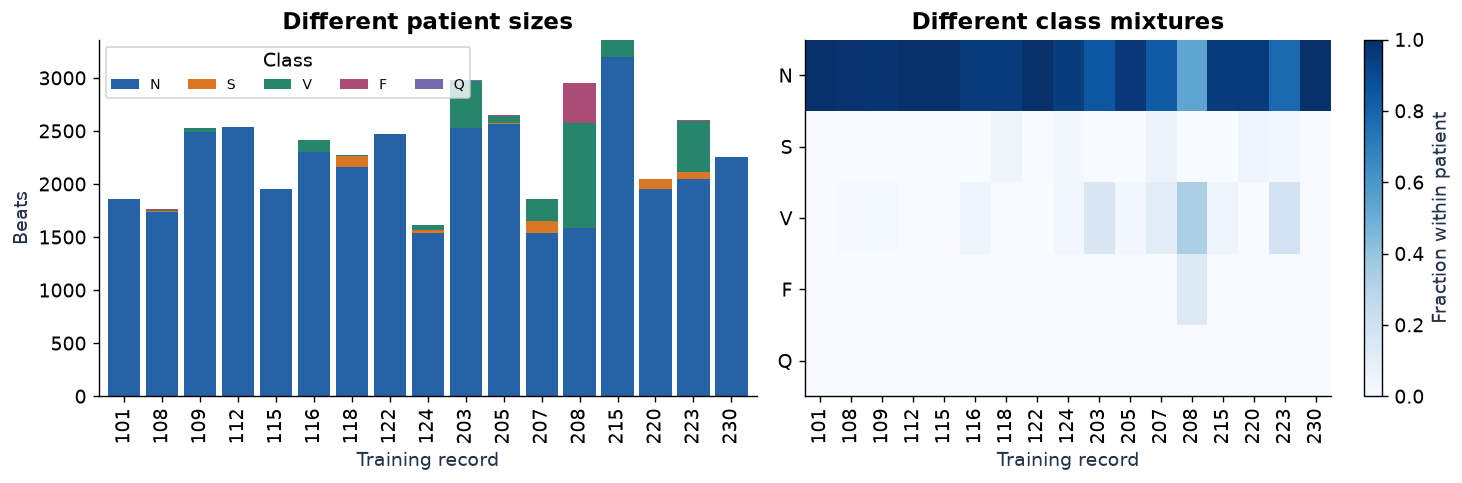

In [5]:
client_counts = support.query("split == 'training'").pivot(index='record', columns='class', values='beats')[CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
client_counts.plot.bar(stacked=True, color=COLORS, ax=axes[0], width=.85)
axes[0].set(title='Different patient sizes', xlabel='Training record', ylabel='Beats')
axes[0].legend(title='Class', ncol=5, fontsize=8)
fractions = client_counts.div(client_counts.sum(axis=1), axis=0)
image = axes[1].imshow(fractions.to_numpy().T, aspect='auto', vmin=0, vmax=1, cmap='Blues')
axes[1].set(yticks=range(5), yticklabels=CLASSES, xticks=range(17),
            xticklabels=client_counts.index.astype(str), title='Different class mixtures', xlabel='Training record')
axes[1].tick_params(axis='x', labelrotation=90)
fig.colorbar(image, ax=axes[1], label='Fraction within patient')
finish(fig)

## Why accuracy needs company

Predicting N for every test beat achieves nearly 89% accuracy while detecting
none of the other four classes. Fixed-five-class macro-F1 gives every class
one fifth of the score, including zero for an unsupported or undetected class.
The validation set contains only four F beats and **no Q beats**, which makes
rare-class model selection fragile.

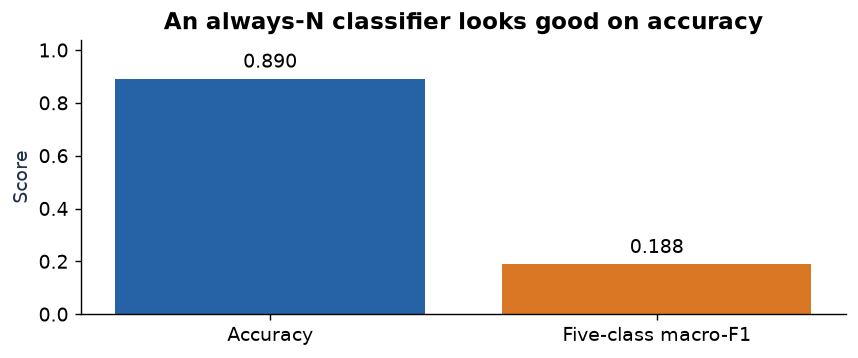

In [6]:
majority = read_json('majority_baseline.json')
counts = split_counts.loc['test'].to_numpy()
accuracy = counts[0] / counts.sum()
macro_f1 = (2 * counts[0] / (counts.sum() + counts[0])) / 5
assert np.isclose(accuracy, majority['accuracy'])
assert np.isclose(macro_f1, majority['macro_f1'])
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.bar(['Accuracy', 'Five-class macro-F1'], [accuracy, macro_f1], color=COLORS[:2])
ax.bar_label(bars, fmt='%.3f', padding=4)
ax.set(ylim=(0, 1.04), ylabel='Score', title='An always-N classifier looks good on accuracy')
finish(fig)

### Try it: which classes can this validation set actually represent?

Before running the next cell, identify the smallest two validation supports.
Would a larger overall validation accuracy answer the rare-class question?

In [7]:
display(split_counts.loc['validation'].sort_values().rename('Validation beats').to_frame())
# Answer: Q has zero examples and F has four. Report support and per-class
# performance alongside accuracy; more beats from N do not fix this limitation.

,Validation beats
class,
Q,0
F,4
S,395
V,1008
N,7490


**Takeaway:** patient separation, class support and client composition are part
of the experiment, not details to fix after choosing a model.

**Optional extension:** use `class_patient_concentration.csv` to find which
single test patient supplies most S or F beats. See how this motivates
patient-aware uncertainty in notebook 3.

**Next:** [2 · Models, objectives and FedAvg](02_models_and_fedavg.ipynb)